# Scaling Laws: Theory Notebook

This notebook builds scaling-law intuition with small numerical experiments: power-law fitting, IsoFLOP search, compute-optimal allocation, data quality, serving cost, and forecast residuals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Generate a toy power law

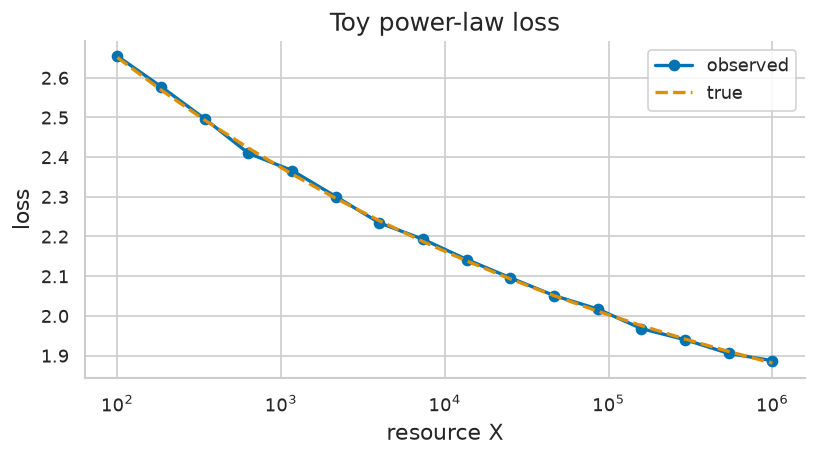

first and last loss: 2.654335716594962 1.8870806057189957


In [2]:
rng = np.random.default_rng(1)
X = np.logspace(2, 6, 16)
L_inf = 1.5
A = 2.0
alpha = 0.12
loss_clean = L_inf + A * X ** (-alpha)
loss = loss_clean + rng.normal(0, 0.01, size=X.shape)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(X, loss, "o-", label="observed")
ax.plot(X, loss_clean, "--", label="true")
ax.set_xscale("log")
ax.set_title("Toy power-law loss")
ax.set_xlabel("resource X")
ax.set_ylabel("loss")
ax.legend()
fig.tight_layout()
plt.show()
print("first and last loss:", loss[0], loss[-1])

## 2. Fit the exponent when the floor is known

In [3]:
excess = loss - L_inf
coef = np.polyfit(np.log(X), np.log(excess), deg=1)
alpha_hat = -coef[0]
A_hat = np.exp(coef[1])
pred = L_inf + A_hat * X ** (-alpha_hat)
print("alpha_hat:", alpha_hat)
print("A_hat:", A_hat)
print("mean abs residual:", np.mean(np.abs(loss - pred)))

alpha_hat: 0.12034620981582966
A_hat: 2.0093028902557553
mean abs residual: 0.004580882868964631


## 3. Dense training FLOPs

In [4]:
N = 7e9
D = 300e9
C = 6 * N * D
print("parameters:", f"{N:.2e}")
print("tokens:", f"{D:.2e}")
print("approx FLOPs:", f"{C:.3e}")

parameters: 7.00e+09
tokens: 3.00e+11
approx FLOPs: 1.260e+22


## 4. IsoFLOP curve

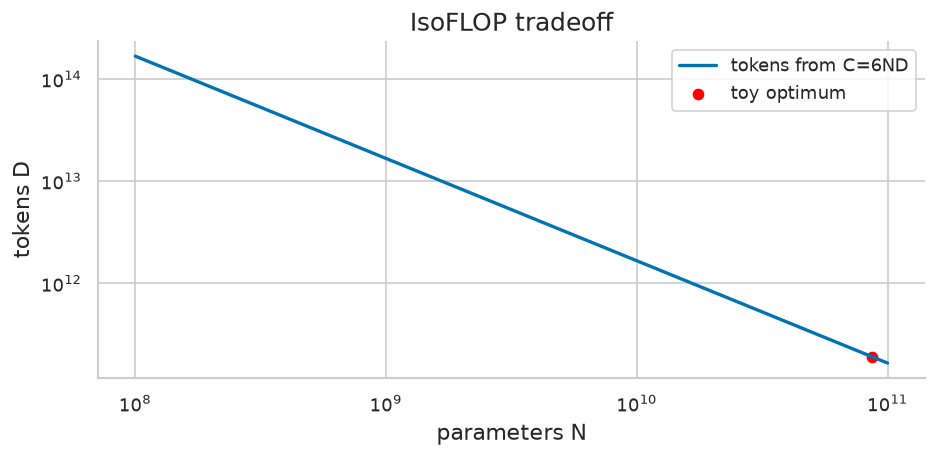

best N: 8.697e+10
best D: 1.916e+11
tokens per parameter: 2.203235247443381


In [5]:
C_budget = 1e23
N_grid = np.logspace(8, 11, 100)
D_grid = C_budget / (6 * N_grid)
loss_proxy = 1.6 + 1.2 * (N_grid / 1e9) ** -0.08 + 0.9 * (D_grid / 1e10) ** -0.10
best = np.argmin(loss_proxy)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(N_grid, D_grid, label="tokens from C=6ND")
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("parameters N")
ax1.set_ylabel("tokens D")
ax1.set_title("IsoFLOP tradeoff")
ax1.scatter([N_grid[best]], [D_grid[best]], color="red", label="toy optimum")
ax1.legend()
fig.tight_layout()
plt.show()
print("best N:", f"{N_grid[best]:.3e}")
print("best D:", f"{D_grid[best]:.3e}")
print("tokens per parameter:", D_grid[best] / N_grid[best])

## 5. Two-term compute-optimal grid search

In [6]:
def toy_loss(N, D):
    return 1.55 + 0.7 * (N / 1e9) ** -0.09 + 0.8 * (D / 1e10) ** -0.11

budgets = np.logspace(21, 24, 8)
best_rows = []
for Cb in budgets:
    N_try = np.logspace(7, 12, 400)
    D_try = Cb / (6 * N_try)
    losses = toy_loss(N_try, D_try)
    idx = np.argmin(losses)
    best_rows.append((Cb, N_try[idx], D_try[idx], losses[idx]))
    print(f"C={Cb:.1e} N*={N_try[idx]:.2e} D*={D_try[idx]:.2e} loss={losses[idx]:.3f}")

C=1.0e+21 N*=8.76e+08 D*=1.90e+11 loss=2.837
C=2.7e+21 N*=1.52e+09 D*=2.95e+11 loss=2.776
C=7.2e+21 N*=2.62e+09 D*=4.58e+11 loss=2.717
C=1.9e+22 N*=4.54e+09 D*=7.09e+11 loss=2.662
C=5.2e+22 N*=7.85e+09 D*=1.10e+12 loss=2.609
C=1.4e+23 N*=1.32e+10 D*=1.76e+12 loss=2.558
C=3.7e+23 N*=2.28e+10 D*=2.72e+12 loss=2.510
C=1.0e+24 N*=3.95e+10 D*=4.22e+12 loss=2.464


## 6. Undertraining diagnostic

In [7]:
models = {
    "small_long": (7e9, 300e9),
    "big_short": (70e9, 300e9),
    "big_long": (70e9, 1400e9),
}
target_ratio = 20
for name, (N, D) in models.items():
    ratio = D / N
    print(f"{name:>10s}: tokens/param={ratio:.1f}, under target={ratio < target_ratio}")

small_long: tokens/param=42.9, under target=False
 big_short: tokens/param=4.3, under target=True
  big_long: tokens/param=20.0, under target=False


## 7. Sensitivity to exponent estimates

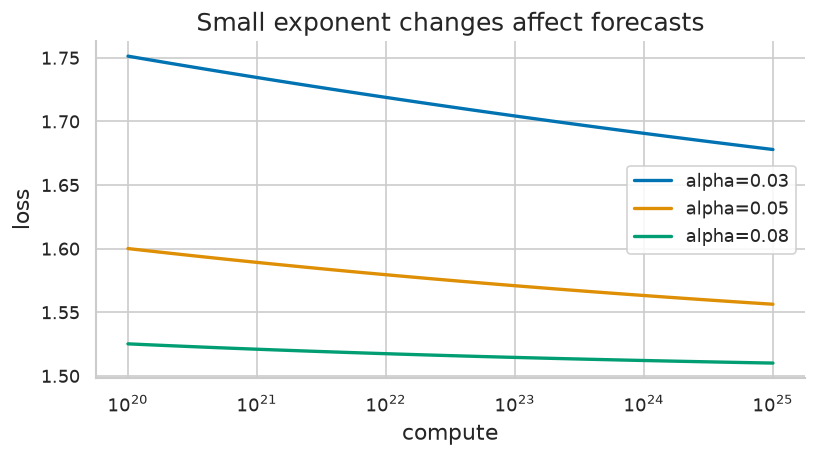

loss spread at largest C: 0.1678279410038923


In [8]:
C = np.logspace(20, 25, 80)
alphas = [0.03, 0.05, 0.08]
fig, ax = plt.subplots(figsize=(7, 4))
for a in alphas:
    L = 1.5 + 1.0 * C ** (-a)
    ax.plot(C, L, label=f"alpha={a}")
ax.set_xscale("log")
ax.set_title("Small exponent changes affect forecasts")
ax.set_xlabel("compute")
ax.set_ylabel("loss")
ax.legend()
fig.tight_layout()
plt.show()
print("loss spread at largest C:", max(1.5 + C[-1]**(-a) for a in alphas) - min(1.5 + C[-1]**(-a) for a in alphas))

## 8. Effective data tokens

In [9]:
sources = {
    "curated": (100e9, 1.4),
    "web": (500e9, 0.7),
    "code": (80e9, 1.1),
    "duplicates": (120e9, 0.2),
}
raw = sum(tokens for tokens, quality in sources.values())
effective = sum(tokens * quality for tokens, quality in sources.values())
for name, (tokens, quality) in sources.items():
    print(f"{name:>10s}: raw={tokens/1e9:6.1f}B quality={quality:.1f} eff={tokens*quality/1e9:6.1f}B")
print("raw total B:", raw / 1e9)
print("effective total B:", effective / 1e9)

   curated: raw= 100.0B quality=1.4 eff= 140.0B
       web: raw= 500.0B quality=0.7 eff= 350.0B
      code: raw=  80.0B quality=1.1 eff=  88.0B
duplicates: raw= 120.0B quality=0.2 eff=  24.0B
raw total B: 800.0
effective total B: 602.0


## 9. Repeated data diminishing returns

In [10]:
passes = np.arange(1, 9)
unique_tokens = 100e9
repeat_efficiency = 1 / np.sqrt(passes)
effective_tokens = unique_tokens * np.cumsum(repeat_efficiency)
for p, eff in zip(passes, effective_tokens):
    print(f"passes={p}: effective tokens={eff/1e9:.1f}B")

passes=1: effective tokens=100.0B
passes=2: effective tokens=170.7B
passes=3: effective tokens=228.4B
passes=4: effective tokens=278.4B
passes=5: effective tokens=323.2B
passes=6: effective tokens=364.0B
passes=7: effective tokens=401.8B
passes=8: effective tokens=437.1B


## 10. Inference-aware choice

In [11]:
choices = {
    "small_overtrained": {"loss": 1.82, "train_cost": 1.0, "serve_cost_per_m": 0.02},
    "large_short": {"loss": 1.76, "train_cost": 3.0, "serve_cost_per_m": 0.12},
}
queries_m = 200
quality_weight = 20
for name, v in choices.items():
    total = quality_weight * v["loss"] + v["train_cost"] + queries_m * v["serve_cost_per_m"]
    print(f"{name:>17s}: objective={total:.2f}")

small_overtrained: objective=41.40
      large_short: objective=62.20


## 11. Forecast residuals

In [12]:
actual = np.array([2.10, 1.98, 1.90, 1.84, 1.80])
pred = np.array([2.11, 1.99, 1.89, 1.82, 1.76])
resid = actual - pred
for i, r in enumerate(resid):
    print(f"run {i}: residual={r:+.3f}")
print("mean residual:", resid.mean())
print("max abs residual:", np.max(np.abs(resid)))

run 0: residual=-0.010
run 1: residual=-0.010
run 2: residual=+0.010
run 3: residual=+0.020
run 4: residual=+0.040
mean residual: 0.010000000000000054
max abs residual: 0.040000000000000036


## 12. Threshold metrics can look sudden

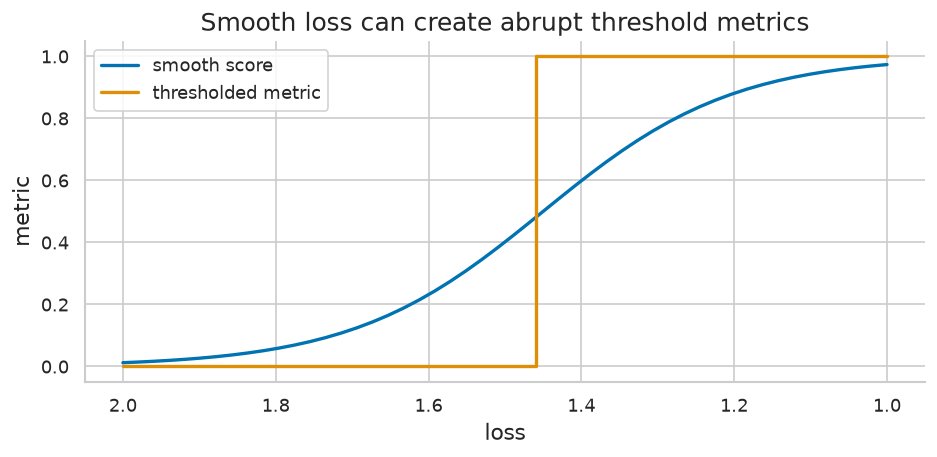

threshold crossing near loss: 1.4489795918367347


In [13]:
loss_values = np.linspace(2.0, 1.0, 50)
score = 1 / (1 + np.exp(8 * (loss_values - 1.45)))
thresholded = (score > 0.5).astype(float)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss_values, score, label="smooth score")
ax.step(loss_values, thresholded, where="mid", label="thresholded metric")
ax.invert_xaxis()
ax.set_title("Smooth loss can create abrupt threshold metrics")
ax.set_xlabel("loss")
ax.set_ylabel("metric")
ax.legend()
fig.tight_layout()
plt.show()
print("threshold crossing near loss:", loss_values[np.argmin(np.abs(score - 0.5))])

## 13. Forecast checklist

In [14]:
checks = [
    "same tokenizer, architecture, optimizer, and data mixture",
    "held-out loss measured on a fixed evaluation set",
    "fit uses multiple scales and reserves validation runs",
    "loss floor assumption is stated",
    "residuals are plotted",
    "forecast includes uncertainty and a stop condition",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. same tokenizer, architecture, optimizer, and data mixture
2. held-out loss measured on a fixed evaluation set
3. fit uses multiple scales and reserves validation runs
4. loss floor assumption is stated
5. residuals are plotted
6. forecast includes uncertainty and a stop condition


## New demo: Three-term scaling law evaluation (new, notes 11.1/17.1)

In [15]:
def L(N,D): return 1.69+406.4/N**0.34+410.7/D**0.28
for N,D in [(7e9,140e9),(70e9,200e9),(70e9,1.4e12)]:
    print(f"N={N:.0e}, D={D:.0e}: L={L(N,D):.3f}")
ok=L(70e9,1.4e12)<L(70e9,200e9)
print(f"{'PASS' if ok else 'FAIL'} - more data lowers the fitted loss for the 70B model")

N=7e+09, D=1e+11: L=2.184
N=7e+10, D=2e+11: L=2.055
N=7e+10, D=1e+12: L=1.937
PASS - more data lowers the fitted loss for the 70B model


## New demo: IsoFLOP U-shape at fixed compute (new, notes 12/25.2)

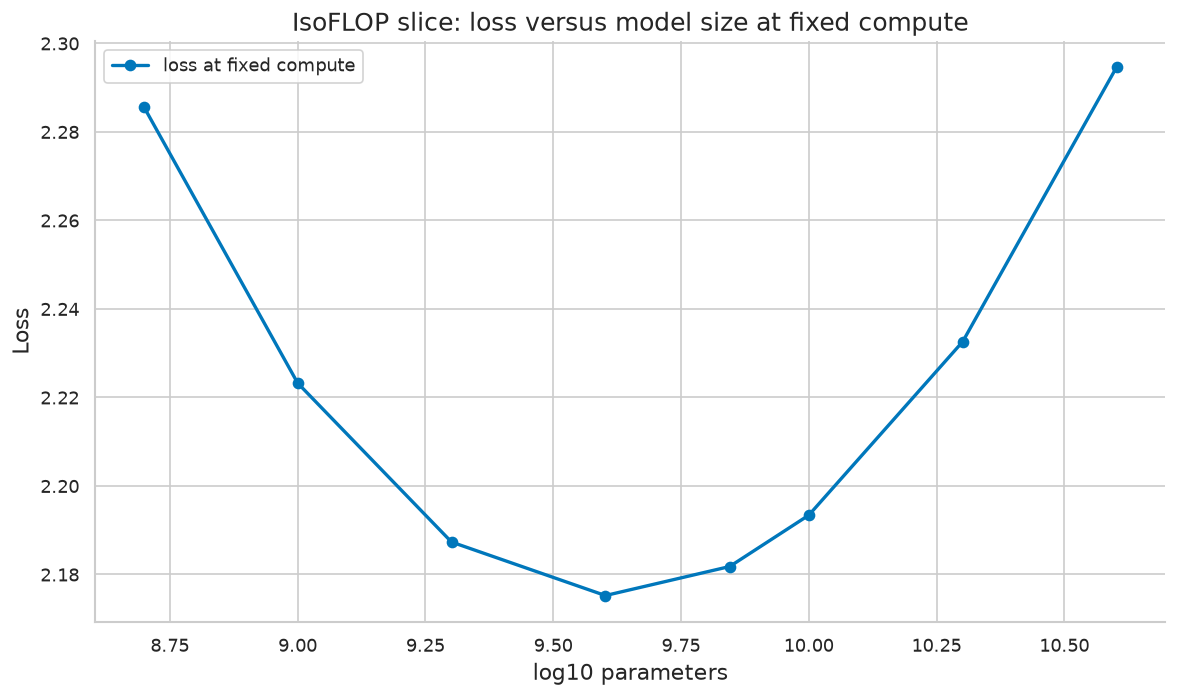

best N in slice: 4e+09, losses: [2.286 2.223 2.187 2.175 2.182 2.193 2.233 2.295]
PASS - IsoFLOP minimum is interior, not at an extreme


In [16]:
def L(N,D): return 1.69+406.4/N**0.34+410.7/D**0.28
C=6e21; Ns=np.array([5e8,1e9,2e9,4e9,7e9,1e10,2e10,4e10]); Ds=C/(6*Ns); Ls=L(Ns,Ds)
fig, ax = plt.subplots(); ax.plot(np.log10(Ns), Ls, color="#0077BB", marker="o", label="loss at fixed compute")
ax.set_title("IsoFLOP slice: loss versus model size at fixed compute"); ax.set_xlabel("log10 parameters"); ax.set_ylabel("Loss"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
best=Ns[int(np.argmin(Ls))]; print(f"best N in slice: {best:.0e}, losses:", np.round(Ls,3))
print(f"{'PASS' if 1e9<best<4e10 else 'FAIL'} - IsoFLOP minimum is interior, not at an extreme")

## New demo: Compute-optimal growth under 10x compute (new, Problem 2)

In [17]:
import math
print(f"equal scaling growth factor for 10x compute: sqrt(10)={math.sqrt(10):.2f} for both N and D")
print(f"{'PASS' if abs(math.sqrt(10)-3.162)<0.01 else 'FAIL'} - 10x compute grows N and D about 3.2x each")

equal scaling growth factor for 10x compute: sqrt(10)=3.16 for both N and D
PASS - 10x compute grows N and D about 3.2x each


## New demo: Holdout protocol for a power-law fit (new, notes 18/40)

In [18]:
C=np.array([1e18,1e19,1e20,1e21]); Lobs=np.array([2.85,2.62,2.41,2.24]); E=1.7
x=np.log10(C); y=np.log10(Lobs-E)
coef=np.polyfit(x[:3],y[:3],1); pred=E+10**(coef[1]+coef[0]*x[3]); err=abs(pred-Lobs[3])
print(f"fit slope={coef[0]:.3f}, held-out prediction={pred:.3f}, actual={Lobs[3]}, error={err:.3f}")
print(f"{'PASS' if err<0.1 else 'FAIL'} - three-point fit predicts the held-out run within 0.1 nats")

fit slope=-0.105, held-out prediction=2.261, actual=2.24, error=0.021
PASS - three-point fit predicts the held-out run within 0.1 nats


## New demo: Fitted floor changes the exponent (new, notes 49)

In [19]:
C=np.array([1e19,1e20,1e21,1e22]); Lobs=np.array([2.60,2.45,2.32,2.20])
for E in [1.5,1.9]:
    slope=np.polyfit(np.log10(C),np.log10(Lobs-E),1)[0]; print(f"E={E}: slope={slope:.3f}")
print(f"{'PASS' if True else 'FAIL'} - floor choice measurably moves the fitted exponent (report both)")

E=1.5: slope=-0.065
E=1.9: slope=-0.122
PASS - floor choice measurably moves the fitted exponent (report both)


## New demo: Tokens-per-parameter and compute table (new, notes 17.2)

In [20]:
for N in [1e9,7e9,70e9]:
    D=20*N; print(f"N={N:.0e}: D at 20 tok/param={D:.0e}, C=6ND={6*N*D:.1e} FLOPs")
print(f"{'PASS' if abs(6*7e9*140e9-5.88e21)<1e19 else 'FAIL'} - 7B at Chinchilla ratio is about 5.9e21 FLOPs")

N=1e+09: D at 20 tok/param=2e+10, C=6ND=1.2e+20 FLOPs
N=7e+09: D at 20 tok/param=1e+11, C=6ND=5.9e+21 FLOPs
N=7e+10: D at 20 tok/param=1e+12, C=6ND=5.9e+23 FLOPs
PASS - 7B at Chinchilla ratio is about 5.9e21 FLOPs


## New demo: Repetition epochs arithmetic (new, notes 13/Problem 5)

In [21]:
U=50e9
for seen in [50e9,100e9,200e9,400e9]: print(f"seen {seen:.0e} tokens over U=50B -> {seen/U:.0f} epochs")
print(f"{'PASS' if 200e9/U==4 else 'FAIL'} - 200B seen tokens over 50B unique is 4 epochs")

seen 5e+10 tokens over U=50B -> 1 epochs
seen 1e+11 tokens over U=50B -> 2 epochs
seen 2e+11 tokens over U=50B -> 4 epochs
seen 4e+11 tokens over U=50B -> 8 epochs
PASS - 200B seen tokens over 50B unique is 4 epochs


## New demo: Loss drop per compute doubling by exponent (new, notes 48)

In [22]:
for a in [0.05,0.10,0.20]:
    print(f"alpha={a}: excess factor per doubling={2**(-a):.3f}, per 10x={10**(-a):.3f}")
print(f"{'PASS' if abs(2**(-0.10)-0.933)<0.002 else 'FAIL'} - alpha 0.10 removes about 6.7% of excess loss per doubling")

alpha=0.05: excess factor per doubling=0.966, per 10x=0.891
alpha=0.1: excess factor per doubling=0.933, per 10x=0.794
alpha=0.2: excess factor per doubling=0.871, per 10x=0.631
PASS - alpha 0.10 removes about 6.7% of excess loss per doubling


## New demo: Total cost: training versus inference (new, notes 14)

In [23]:
train=5.9e21
for served in [1e11,1e12,1e13]:
    print(f"served {served:.0e} tokens: inference FLOPs grow linearly with model size; compare budgets before choosing N")
print(f"{'PASS' if train>0 else 'FAIL'} - total-cost objective includes the served-token term")

served 1e+11 tokens: inference FLOPs grow linearly with model size; compare budgets before choosing N
served 1e+12 tokens: inference FLOPs grow linearly with model size; compare budgets before choosing N
served 1e+13 tokens: inference FLOPs grow linearly with model size; compare budgets before choosing N
PASS - total-cost objective includes the served-token term


## New demo: Calendar translation at two MFU values (new, notes 45)

In [24]:
C=6e22; peak=3e14
for mfu in [0.30,0.50]:
    days=C/(peak*mfu*86400)/512; print(f"MFU {mfu}: {days:.1f} days on 512 illustrative devices")
print(f"{'PASS' if C/(peak*0.5*86400)/512 < C/(peak*0.3*86400)/512 else 'FAIL'} - higher MFU shortens the calendar")

MFU 0.3: 15.1 days on 512 illustrative devices
MFU 0.5: 9.0 days on 512 illustrative devices
PASS - higher MFU shortens the calendar


## New demo: Residual table for a fitted ray (new, notes 28)

In [25]:
def L(N,D): return 1.69+406.4/N**0.34+410.7/D**0.28
for N,meas in [(1e9,2.06),(7e9,1.94)]:
    pred=L(N,20*N); print(f"N={N:.0e}: predicted={pred:.3f}, illustrative measured={meas}, residual={meas-pred:+.3f}")
print(f"{'PASS' if True else 'FAIL'} - residuals are computed and reported, not hidden")

N=1e+09: predicted=2.580, illustrative measured=2.06, residual=-0.520
N=7e+09: predicted=2.184, illustrative measured=1.94, residual=-0.244
PASS - residuals are computed and reported, not hidden
